# Gold layer: Kolumbus punctuality

Gold turns the Silver stop calls into punctuality tables. Each actual time is compared with the
**live schedule** (`et_aimed`, SIRI ET) and the **printed timetable** (`netex_planned`, NeTEx).

Code: `src/pipeline/Gold/`. Run (about 50 min):

```bash
bash src/pipeline/Gold/scripts/run_gold_2026.sh gold-kol-53d-2026-v2
```

This notebook only reads the published run.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import pyarrow.dataset as ds

GOLD = Path("/srv/dat535/data/gold/kol/runs/gold-kol-53d-2026-v2")
manifest = json.loads((GOLD / "gold_manifest.json").read_text())
read = lambda name, **kw: pd.read_parquet(GOLD / name, **kw)

print("Run:", manifest["gold_run_id"], "| gate:", manifest["gate_status"])
print("Days:", len(manifest["published_operating_dates"]), "sampled,",
      manifest["published_operating_dates"][0], "to", manifest["published_operating_dates"][-1])

Run: gold-kol-53d-2026-v2 | gate: passed
Days: 53 sampled, 2026-01-01 to 2026-11-19


## How Gold is built

`build_gold.py` runs the steps below in one Spark job. Each file in `src/pipeline/Gold/` does one part:

| File | What it does |
| --- | --- |
| `__init__.py` | Shared settings: the on-time rules, seasons, default paths |
| `inputs.py` | Finds one checked Silver run for every date (stops if a date is missing) |
| `event_metrics.py` | Turns every stop call into arrival and departure events against both schedules, then counts on time, late and very late per day, line and stop |
| `journey_metrics.py` | One row per trip (first and last stop delay), trips scheduled, tracked and cancelled per line, and the season/month tables |
| `quality_and_publish.py` | Data quality per day, checks that must pass, then writes the 9 tables and `gold_manifest.json` |
| `build_gold.py` | Starts Spark and runs the steps in order |

```text
Silver runs ─► inputs ─► events ─► daily / period punctuality (network, line, stop)
                     └─► trips  ─► line service ─► quality gate ─► publish
```

## 1. Tables

In [2]:
tables = ["daily_network_punctuality", "period_network_punctuality", "daily_line_punctuality",
          "period_line_punctuality", "daily_stop_punctuality", "daily_line_service", "period_line_service",
          "journey_performance", "daily_data_quality"]
pd.DataFrame({"rows": [ds.dataset(GOLD / t).count_rows() for t in tables]}, index=tables)

,rows
daily_network_punctuality,212
period_network_punctuality,180
daily_line_punctuality,39716
period_line_punctuality,16090
daily_stop_punctuality,877484
daily_line_service,25282
period_line_service,8056
journey_performance,1117443
daily_data_quality,53


## 2. Rules

On time: a departure 0 to 5 min late (earlier is early), an arrival at most 5 min late.
Very late: more than 15 min. Estimated or missing times are excluded.

In [3]:
pd.Series(manifest["metric_policy"]).to_frame("value")

,value
timezone,Europe/Oslo
departure_early_max_exclusive_sec,0.0
departure_within_window_max_sec,300.0
arrival_within_limit_max_sec,300.0
severe_delay_min_exclusive_sec,900.0
timestamp_identity_tolerance_sec,0.001
business_agreement_tolerance_sec,0.0


## 3. On time by season (departures)

In [4]:
net = read("period_network_punctuality")
season = net[(net.period_type == "season") & (net.event_type == "departure") & net.transport_mode.isin(["bus", "water"])]
(season.pivot_table(index="period_label", columns=["transport_mode", "baseline"], values="within_window_rate")
       .reindex(list(manifest["season_windows_2026"])).style.format("{:.1%}"))

Each season is a sample of days, not every day:

In [5]:
(season[(season.transport_mode == "bus") & (season.baseline == "et_aimed")]
 .set_index("period_label")[["selected_date_count", "weekday_date_counts"]])

,selected_date_count,weekday_date_counts
period_label,,
autumn-2026,14,"[(Tue, 5), (Thu, 6), (Sun, 3)]"
spring-2026,15,"[(Fri, 5), (Sun, 5), (Wed, 5)]"
summer-2026,15,"[(Wed, 5), (Sat, 5), (Mon, 5)]"
winter-2026,9,"[(Thu, 5), (Sun, 4)]"


## 4. On time by month (live schedule)

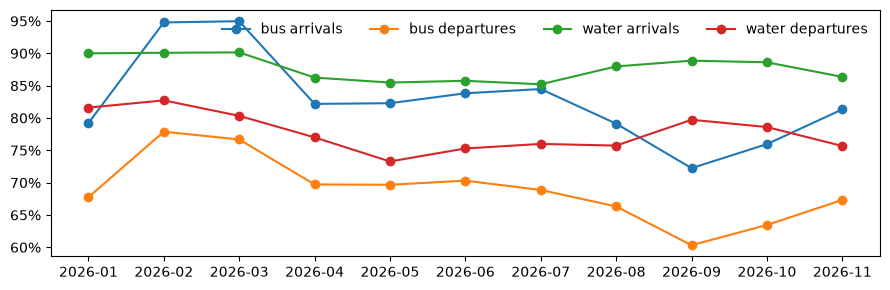

In [6]:
month = net[(net.period_type == "month") & (net.baseline == "et_aimed") & net.transport_mode.isin(["bus", "water"])]
fig, ax = plt.subplots(figsize=(9, 3))
for (mode, event), g in month.groupby(["transport_mode", "event_type"]):
    g = g.sort_values("period_label")
    ax.plot(g.period_label, g.within_window_rate, marker="o", label=f"{mode} {event}s")
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.legend(ncol=4, frameon=False)
plt.tight_layout()

## 5. Lines most often late (summer 2026, bus departures)

Lines with at least 100 measured departures, against the live schedule. Delays are in minutes.

In [7]:
lines = read("period_line_punctuality")
lines = lines[(lines.period_label == "summer-2026") & (lines.transport_mode == "bus") & (lines.event_type == "departure")
              & (lines.baseline == "et_aimed") & lines.line_id.notna() & (lines.eligible_event_count >= 100)]
worst = lines.sort_values("late_rate", ascending=False).head(10)
worst.assign(median_min=worst.median_delay_sec / 60, p95_min=worst.p95_delay_sec / 60)[
    ["line_public_code", "within_window_rate", "late_rate", "severe_delay_rate", "median_min", "p95_min",
     "eligible_event_count"]].round(3)

,line_public_code,within_window_rate,late_rate,severe_delay_rate,median_min,p95_min,eligible_event_count
16082,9,0.159,0.720,0.579,18.337,73.857,328
1043,10,0.481,0.451,0.096,4.296,18.821,19878
3984,58,0.457,0.402,0.041,3.508,13.811,468
10806,SK4910,0.439,0.369,0.181,2.875,24.745,946
4689,X39,0.556,0.355,0.047,3.538,13.929,3518
9520,152,0.528,0.347,0.019,3.695,10.260,216
3246,21,0.658,0.311,0.024,3.395,11.888,28790
15196,140,0.637,0.303,0.023,3.297,10.484,7624
9016,242,0.650,0.299,0.051,1.496,15.738,117
542,5,0.617,0.299,0.057,2.788,15.774,80051


## 6. Stops most often late (summer 2026, bus departures)

Gold only stores quay IDs, so stop names come from Silver. At least 200 measured departures.

In [8]:
SILVER = Path("/srv/dat535/data/silver/kol/runs")
names = pd.concat(pd.read_parquet(run / "journey_pattern_stops", columns=["quay_id", "stop_point_name"])
                  for run in sorted(SILVER.glob("*/"))).dropna().drop_duplicates("quay_id")
names = dict(zip(names.quay_id, names.stop_point_name))

start, end = (pd.Timestamp(d).date() for d in manifest["season_windows_2026"]["summer-2026"])
stops = read("daily_stop_punctuality", columns=["quay_id", "eligible_event_count", "late_count"],
             filters=[("operating_date", ">=", start), ("operating_date", "<=", end), ("transport_mode", "==", "bus"),
                      ("event_type", "==", "departure"), ("baseline", "==", "et_aimed")]).groupby("quay_id").sum()
stops = stops[stops.eligible_event_count >= 200].assign(late_rate=lambda f: f.late_count / f.eligible_event_count,
                                                        stop=lambda f: f.index.map(names))
stops.sort_values("late_rate", ascending=False).head(10)[["stop", "late_rate", "eligible_event_count"]].round(3)

,stop,late_rate,eligible_event_count
quay_id,,,
NSR:Quay:48451,Askjekrysset,0.683,262
NSR:Quay:45027,Harestad E39,0.587,264
NSR:Quay:44907,Ryggleet,0.543,221
NSR:Quay:48613,Randaberg kommunehus,0.536,222
NSR:Quay:49186,Goaveien,0.529,221
NSR:Quay:49088,Gauselsenteret,0.527,596
NSR:Quay:46031,Husaberget,0.520,596
NSR:Quay:49419,Daleveien,0.519,551
NSR:Quay:49424,Dalveien,0.505,222


## 7. New lines, ended lines and route changes (bus)

From the planned stop calls in Silver. A line is its public number, so a new internal ID with the same
number is not a new line. Only 53 days are sampled, so a change happened between the line's previous
sampled run and the date shown. 1 January (holiday service) is skipped, a line or stop must appear on
at least 3 sampled days, and the last 14 days are ignored for "ended" (weekend-only lines).

In [9]:
served = pd.concat(
    pd.read_parquet(run / "netex_stop_calls",
                    columns=["operating_date", "resolved_public_code", "resolved_transport_mode", "quay_id"])
    .dropna().drop_duplicates() for run in sorted(SILVER.glob("*/")))
served.columns = ["date", "line", "mode", "quay_id"]
served = served[served["mode"] == "bus"].assign(date=lambda f: pd.to_datetime(f.date))
first_regular, end_cutoff = pd.Timestamp("2026-01-08"), served.date.max() - pd.Timedelta(days=14)

span = served.groupby("line").date.agg(first="min", last="max", days="nunique")
started = (span["first"] > first_regular) & (span.days >= 3)
ended = (span["last"] < end_cutoff) & (span.days >= 3)
span["what"] = None
span.loc[started, "what"], span.loc[ended, "what"] = "started", "ended"
span.loc[started & ended, "what"] = "ran for a while"
span.dropna().sort_values("first")

,first,last,days,what
line,,,,
X77,2026-01-08,2026-06-29,18,ended
162,2026-01-08,2026-04-01,5,ended
46,2026-01-08,2026-06-22,16,ended
67,2026-01-08,2026-06-29,17,ended
SK0108,2026-01-08,2026-06-15,14,ended
163,2026-04-01,2026-07-29,14,ran for a while
SK6021,2026-04-08,2026-06-22,8,ran for a while
SK6023,2026-04-08,2026-04-29,4,ran for a while
N96,2026-05-01,2026-08-29,10,ran for a while


In [10]:
stops_ = served.groupby(["line", "quay_id"]).date.agg(["min", "max", "nunique"]).reset_index().join(
    span[["first", "last"]], on="line")
added = stops_[(stops_["min"] > stops_["first"]) & (stops_["min"] > first_regular) & (stops_["nunique"] >= 3)]
dropped = stops_[(stops_["max"] < stops_["last"]) & (stops_["max"] < end_cutoff) & (stops_["nunique"] >= 3)]
routes = pd.concat([added.groupby(["line", "min"]).size().rename("stops_added"),
                    dropped.groupby(["line", "max"]).size().rename("stops_dropped (last seen)")], axis=1).fillna(0)
routes = routes[routes.sum(axis=1) >= 3]
print(len(routes), "route changes of 3 or more stops; the biggest:")
routes.sort_values("stops_added", ascending=False).head(10).astype(int)

157 route changes of 3 or more stops; the biggest:


,,stops_added,stops_dropped (last seen)
line,,,
4,2026-07-01,85,0
1,2026-07-01,64,0
9,2026-07-01,58,0
SK6024,2026-09-01,24,0
42,2026-07-01,20,0
SK4911,2026-04-08,20,0
SK4917,2026-04-08,19,0
2,2026-07-01,18,0
SK4926,2026-04-08,18,0


## 8. Check: network, line and stop totals agree every day

In [11]:
totals = pd.DataFrame({t: read(t, columns=["operating_date", "eligible_event_count"])
                          .groupby("operating_date").eligible_event_count.sum()
                       for t in ["daily_network_punctuality", "daily_line_punctuality", "daily_stop_punctuality"]})
print("days:", len(totals), "| all agree:", (totals.nunique(axis=1) == 1).all())

days: 53 | all agree: True


In [12]:
dq = read("daily_data_quality").sort_values("operating_date")
print("Days without live feed:", (~dq.siri_file_available.astype(bool)).sum(), "of", len(dq))
dq[["planned_call_matching_coverage", "reported_call_matching_coverage"]].describe().loc[["min", "mean", "max"]].round(3)

Days without live feed: 0 of 53


,planned_call_matching_coverage,reported_call_matching_coverage
min,0.000,0.000
mean,0.914,0.943
max,0.979,1.000
